# Comparative Analysis — LeJEPA vs Random Init × NYU vs KITTI

Loads up to 4 fine-tuned models and produces a full comparative analysis:

- Test-set metrics (RMSE / AbsRel / δ₁) per (variant, dataset)
- Bar chart grid 2×3 (datasets × metrics)
- Side-by-side depth predictions per dataset
- PCA probing per variant per dataset
- Efficiency benchmark (once — same arch)
- Convergence curves overlay (LeJEPA vs Random init, per dataset)
- Final unified comparison table (CSV)

Configuration is in **section 1**. Edit there and re-run; nothing else needs touching.

## Imports

Standard packages and project modules used by the analysis notebook.


In [1]:
# This notebook lives in `extra/`. Move CWD up to project root.
import os, sys
from pathlib import Path

if Path.cwd().name == "extra":
    os.chdir(Path.cwd().parent)
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"[INFO] Project root: {PROJECT_ROOT}")


[INFO] Project root: /Volumes/Lexar/CV-project-25-26


In [2]:
import json
import time
import glob
import random
import gc

import numpy as np
import torch
import lightning as L
import matplotlib.pyplot as plt
import pandas as pd


In [3]:
from src.config import (
    DEVICE,
    ARCH_TYPE,
    FT_BATCH_SIZE,
    NYU_SIZE,
    KITTI_SIZE,
    DATASET_NYU_PATH,
    DATASET_KITTI_PATH,
    MODEL_SAVE_PATH,
    OUTPUT_DIR,
    IMAGES_DIR,
    JSON_DIR,
)
from src.network    import METERModel
from src.dataset    import DepthEstimationDataset, build_dataloader
from src.train      import METERFinetune
from src.evaluation import (
    evaluate_depth_model,
    evaluate_pixel_weighted,
    geometric_probing_test_set,
    extract_features,
    features_to_pca,
    plot_pca_embeddings,
    denorm_rgb,
    predict_depth,
    benchmark_model,
    smooth,
    per_epoch,
    find_logger_csvs,
    first_epoch_reaching,
    extract_total_flops,
)
from src.utils      import (
    save_dict_to_json,
    load_dict_from_json,
    set_seeds,
    find_checkpoint,
    find_ssl_ckpt,
)

print("[OK] Project modules imported")


[OK] Project modules imported


## Globals

Environment settings and reproducibility state shared by the analysis notebook.


In [4]:
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
L.seed_everything(SEED, workers=True)

if torch.cuda.is_available() and torch.cuda.get_device_name(0) == "Tesla T4":
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_ROOT = "/content/drive/MyDrive/CV-project-25-26"
        if DRIVE_ROOT not in sys.path:
            sys.path.insert(0, DRIVE_ROOT)
        os.chdir(DRIVE_ROOT)
        print(f"[INFO] Colab T4 — CWD: {os.getcwd()}")
    except Exception as e:
        print(f"[INFO] Not on Colab ({e})")

print("[OK] Environment ready")


Seed set to 42


[OK] Environment ready


### Analysis Configuration

Notebook-wide analysis variables: architecture, datasets, variants, and output folders.


In [5]:
# ====== USER CONFIG ======
ARCH_NAME = ARCH_TYPE          # "xxs" | "xs" | "s"

# Datasets to include in the analysis
DATASETS = ["nyu", "kitti"]    # set to e.g. ["nyu"] if you only ran NYU

# Variants to compare
VARIANTS = {
    "lejepa": {
        "ckpt_dir" : "finetune",                  # subfolder under MODEL_SAVE_PATH
        "log_name" : "meter_finetune_{dataset}_{ARCH_NAME}",    # CSVLogger 'name' parameter
        "label"    : "LeJEPA-METER",
        "color"    : "#3498db",
    },
    "from_scratch": {
        "ckpt_dir" : "supervised",
        "log_name" : "meter_sl_{dataset}_{ARCH_NAME}",
        "label"    : "Random init",
        "color"    : "#e67e22",
    },
}

# Number of samples used in visualization grids
NUM_VIS_SAMPLES = 3
# ==========================

ARCH_NAME = ARCH_NAME.lower()
print(f"Architecture : METER-{ARCH_NAME.upper()}")
print(f"Datasets     : {DATASETS}")
print(f"Variants     : {list(VARIANTS.keys())}")

# Output dirs (created if missing)
for p in (OUTPUT_DIR, IMAGES_DIR, JSON_DIR):
    Path(p).mkdir(parents=True, exist_ok=True)
(Path(OUTPUT_DIR) / "csv").mkdir(parents=True, exist_ok=True)


Architecture : METER-XXS
Datasets     : ['nyu', 'kitti']
Variants     : ['lejepa', 'from_scratch']


## Utils

Checkpoint discovery uses helper functions imported from `src.utils`.


In [6]:
print("=== CHECKPOINT DISCOVERY ===\n")
checkpoints = {}   # (variant, dataset) -> Path
for variant_key, vinfo in VARIANTS.items():
    for dataset in DATASETS:
        ckpt_subdir = vinfo["ckpt_dir"].format(dataset=dataset)
        ckpt        = find_checkpoint(ckpt_subdir, dataset, ARCH_NAME)
        checkpoints[(variant_key, dataset)] = ckpt
        tag = f"{vinfo['label']:20s} | {dataset:5s}"
        if ckpt is None:
            print(f"  [MISS] {tag} → none in {ckpt_subdir}/")
        else:
            mb = ckpt.stat().st_size / 1e6
            print(f"  [ OK ] {tag} → {ckpt.name}  ({mb:.1f} MB)")


=== CHECKPOINT DISCOVERY ===

  [ OK ] LeJEPA-METER         | nyu   → best-epoch=31-val_delta1=0.0000-nyu-xxs.ckpt  (8.8 MB)
  [ OK ] LeJEPA-METER         | kitti → best-epoch=56-val_delta1=0.0000-kitti-xxs.ckpt  (8.8 MB)
  [ OK ] Random init          | nyu   → best-epoch=36-val_delta1=0.0000-nyu-xxs.ckpt  (8.8 MB)
  [ OK ] Random init          | kitti → best-epoch=36-val_delta1=0.0000-kitti-xxs.ckpt  (8.8 MB)


## Data

Test and visualization dataloaders used by the evaluation workflow.


In [7]:
print("=== BUILDING TEST DATALOADERS ===")

test_loaders, vis_loaders = {}, {}

if "nyu" in DATASETS:
    try:
        nyu_test = DepthEstimationDataset(
            dataset = "nyu",
            path    = DATASET_NYU_PATH,
            mode    = "finetune",
            depth   = True,
            split   = "test",
            cache_on_disk = False,
        )
        if len(nyu_test) == 0:
            print("[WARN] NYU test set is empty — skipping NYU")
        else:
            test_loaders["nyu"] = build_dataloader(
                nyu_test, batch_size=16, shuffle=False, drop_last=False)
            vis_loaders["nyu"]  = build_dataloader(
                nyu_test, batch_size=NUM_VIS_SAMPLES, shuffle=True, drop_last=True)
            print(f"[OK] NYU   loader — {len(nyu_test)} samples")
    except Exception as e:
        print(f"[FAIL] NYU build failed: {e}")

if "kitti" in DATASETS:
    try:
        kitti_test = DepthEstimationDataset(
            dataset = "kitti",
            path    = DATASET_KITTI_PATH,
            mode    = "finetune",
            depth   = True,
            split   = "test",
            cache_on_disk = False,
        )
        if len(kitti_test) == 0:
            print("[WARN] KITTI val set is empty")
        else:
            test_loaders["kitti"] = build_dataloader(
                kitti_test, batch_size=16, shuffle=False, drop_last=False)
            vis_loaders["kitti"]  = build_dataloader(
                kitti_test, batch_size=NUM_VIS_SAMPLES, shuffle=True, drop_last=True)
            print(f"[OK] KITTI loader — {len(kitti_test)} samples")
    except Exception as e:
        print(f"[FAIL] KITTI build failed: {e}")

print(f"Available test loaders : {list(test_loaders.keys())}")
print(f"Available vis loaders  : {list(vis_loaders.keys())}")

=== BUILDING TEST DATALOADERS ===

[INFO] Initializing NYU dataset
[INFO] Mode: finetune
[INFO] NYU split: test
[INFO] NYU RGB-depth pairs found: 654
[INFO] Target resolution (H, W): (192, 256)
[INFO] Total samples: 654

[INFO] Building DataLoader
[INFO] Batch size:   16
[INFO] Num workers:  4
[INFO] Device:       mps
[INFO] DataLoader ready

[INFO] Building DataLoader
[INFO] Batch size:   3
[INFO] Num workers:  4
[INFO] Device:       mps
[INFO] DataLoader ready
[OK] NYU   loader — 654 samples

[INFO] Initializing KITTI dataset
[INFO] Mode: finetune
[INFO] KITTI splits: ('test',)
[INFO] GT files in split 'test': 652
[INFO] Valid KITTI RGB-depth pairs: 652
[INFO] Target resolution (H, W): (192, 636)
[INFO] Total samples: 652

[INFO] Building DataLoader
[INFO] Batch size:   16
[INFO] Num workers:  4
[INFO] Device:       mps
[INFO] DataLoader ready

[INFO] Building DataLoader
[INFO] Batch size:   3
[INFO] Num workers:  4
[INFO] Device:       mps
[INFO] DataLoader ready
[OK] KITTI loader —

## Evaluation

Load trained checkpoints and run the test-set evaluation for each available configuration.


In [8]:
print("=== EVALUATION LOOP ===\n")

results = {}
models  = {}

for (variant_key, dataset), ckpt in checkpoints.items():
    label = VARIANTS[variant_key]["label"]
    tag   = f"[{label} | {dataset.upper()}]"

    if ckpt is None:
        print(f"{tag} SKIP — no checkpoint")
        continue
    if dataset not in test_loaders:
        print(f"{tag} SKIP — no test loader for {dataset}")
        continue

    # Reset RNG state before each model load + eval — full determinism
    set_seeds(42)

    print(f"{tag} loading {ckpt.name} …")
    try:
        model = METERFinetune.load_from_checkpoint(
            str(ckpt),
            dataset_name=dataset,
        ).to(DEVICE)
        model.eval()
    except Exception as e:
        print(f"{tag} FAIL — could not load: {e}")
        continue

    train_time_sec = float(getattr(model, "total_train_time", 0.0) or 0.0)

    print(f"{tag} evaluating on {len(test_loaders[dataset].dataset)} samples …")
    t0 = time.time()
    metrics = evaluate_pixel_weighted(
        model        = model,
        dataloader   = test_loaders[dataset],
        device       = DEVICE,
        dataset_name = dataset,
    )
    elapsed = time.time() - t0
    print(f"{tag} done in {elapsed:.1f} s — "
          f"RMSE={metrics['RMSE']:.4f}  AbsRel={metrics['AbsRel']:.4f}  Delta1={metrics['Delta1']:.4f}")

    results[(variant_key, dataset)] = {
        **metrics,
        "train_time_sec": train_time_sec,
        "eval_time_sec" : elapsed,
        "checkpoint"    : str(ckpt),
        "variant"       : variant_key,
        "dataset"       : dataset,
        "arch"          : ARCH_NAME,
    }
    models[(variant_key, dataset)] = model

print(f"\nEvaluated configurations: {len(results)} / {len(checkpoints)}")
print("Note: pixel-weighted aggregation, no augmentation, seeded RNG → deterministic across runs")

=== EVALUATION LOOP ===

[LeJEPA-METER | NYU] loading best-epoch=31-val_delta1=0.0000-nyu-xxs.ckpt …

[INFO] Initializing fine-tuning model (Baseline=False, Dataset=nyu)

[INFO] Building METER-xxs (Baseline=False)
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
[WARNING] Checkpoint not found: /content/drive/MyDrive/CV-project-25-26/models/checkpoints/pretrain/last.ckpt
[INFO] Fine-tuning model ready
[LeJEPA-METER | NYU] evaluating on 654 samples …
[LeJEPA-METER | NYU] done in 20.5 s — RMSE=0.7709  AbsRel=0.2046  Delta1=0.6855
[LeJEPA-METER | KITTI] loading best-epoch=56-val_delta1=0.0000-kitti-xxs.ckpt …

[INFO] Initializing fine-tuning model (Baseline=False, Dataset=nyu)

[INFO] Building METER-xxs (Baseline=False)
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
[WARNING] Checkpoint not found: /content/drive/MyDrive/CV-project-25-26/models/checkpoints/pretrain/last.ckpt
[INFO] Fine-tuning model ready
[LeJEPA-METER | KITTI] evaluating on 652 samples …
[LeJEPA

/Volumes/Lexar/CV-project-25-26/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/migration/utils.py:56: The loaded checkpoint was produced with Lightning v2.6.5, which is newer than your current Lightning version: v2.6.4


[Random init | KITTI] done in 6.6 s — RMSE=4.9876  AbsRel=0.1232  Delta1=0.8427

Evaluated configurations: 4 / 4
Note: pixel-weighted aggregation, no augmentation, seeded RNG → deterministic across runs


### 5 — Zero-shot Geometric Probing (BEFORE fine-tuning)

Project 7 Objective 2: "Before adding the depth decoder, analyze the latent space
using PCA. Evaluate if the 'free' semantic segments emerging from LeJEPA align
with depth discontinuities". Compare the SSL encoder (no fine-tuning, no decoder)
against a random encoder as a control. For each dataset it shows: RGB, GT depth,
LeJEPA SSL encoder PCA, and random-init encoder PCA.

=== ZERO-SHOT GEOMETRIC PROBING (pre fine-tuning) ===


[INFO] Building METER-xxs (Baseline=False)
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464

--- NYU — SSL ckpt: last_nyu.ckpt ---

[INFO] Building METER-xxs (Baseline=False)
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
[INFO] SSL encoder loaded — missing=0, unexpected=0


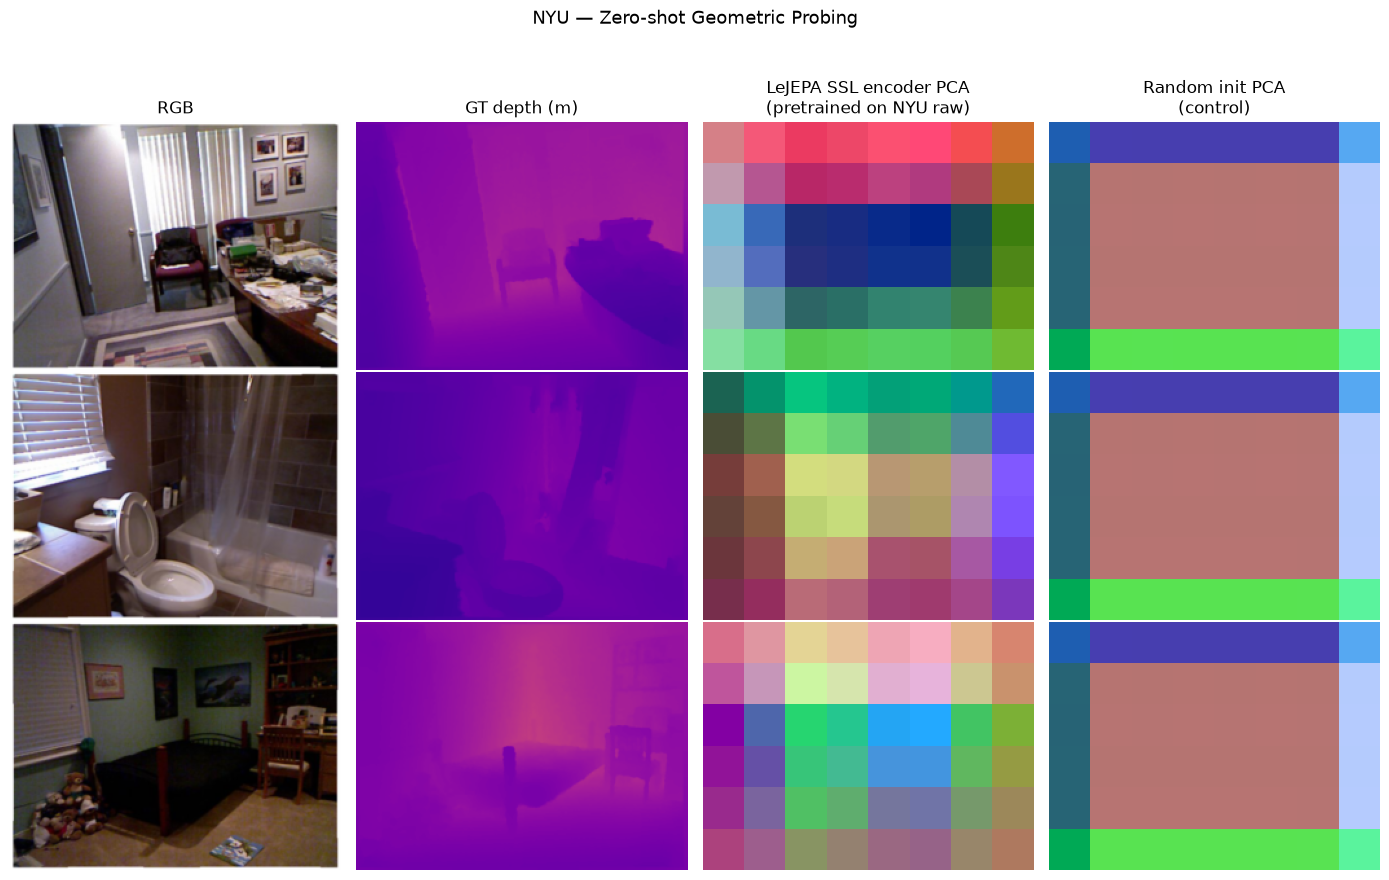

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/zero_shot_probing_nyu_xxs.pdf

--- KITTI — SSL ckpt: last_kitti.ckpt ---

[INFO] Building METER-xxs (Baseline=False)
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
[INFO] SSL encoder loaded — missing=0, unexpected=0


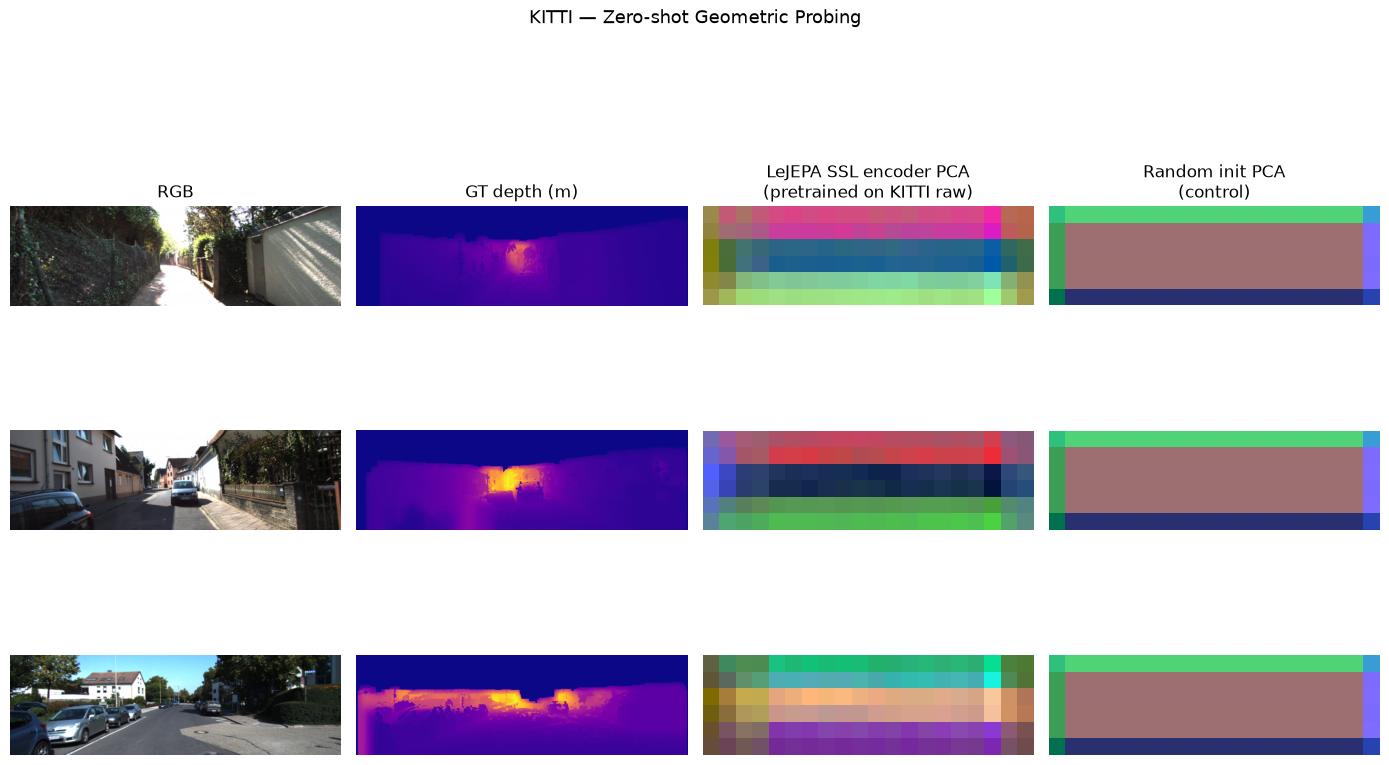

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/zero_shot_probing_kitti_xxs.pdf


In [9]:
print("=== ZERO-SHOT GEOMETRIC PROBING (pre fine-tuning) ===\n")

# Random encoder shared across datasets (it's truly random, no dataset dependency)
random_encoder_model = METERModel(arch_type=ARCH_NAME).to(DEVICE)
random_encoder_model.eval()

for dataset in DATASETS:
    if dataset not in vis_loaders:
        print(f"[SKIP {dataset}] no vis loader")
        continue

    ssl_ckpt_path = find_ssl_ckpt(dataset)
    if ssl_ckpt_path is None:
        print(f"[SKIP {dataset}] no SSL ckpt found under ssl_{dataset}/")
        continue

    print(f"\n--- {dataset.upper()} — SSL ckpt: {ssl_ckpt_path.name} ---")

    # Load SSL encoder weights into a fresh METER (no fine-tuning, no decoder use)
    ssl_encoder_model = METERModel(arch_type=ARCH_NAME).to(DEVICE)
    ckpt = torch.load(ssl_ckpt_path, map_location="cpu", weights_only=False)
    state = ckpt.get("state_dict", ckpt)
    enc_state = {}
    for k, v in state.items():
        if k.startswith("encoder."):
            enc_state[k[len("encoder."):]] = v
        elif k.startswith("model.encoder."):
            enc_state[k[len("model.encoder."):]] = v
    msg = ssl_encoder_model.encoder.load_state_dict(enc_state, strict=False)
    print(f"[INFO] SSL encoder loaded — missing={len(msg.missing_keys)}, "
          f"unexpected={len(msg.unexpected_keys)}")
    ssl_encoder_model.eval()

    batch = next(iter(vis_loaders[dataset]))
    rgb, depth_gt = batch
    rgb_show = denorm_rgb(rgb)
    gt_scale = 1.0
    gt_unit  = "m"
    gt_vmax  = 10.0 if dataset == "nyu" else 80.0
    gt_show  = (depth_gt.cpu() * gt_scale)

    n = rgb.shape[0]
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.0 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        axes[i, 0].imshow(rgb_show[i].permute(1, 2, 0).numpy())
        axes[i, 0].set_title("RGB" if i == 0 else ""); axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_show[i, 0].numpy(), cmap="plasma", vmin=0, vmax=gt_vmax)
        axes[i, 1].set_title(f"GT depth ({gt_unit})" if i == 0 else "")
        axes[i, 1].axis("off")

        feat_ssl = extract_features(ssl_encoder_model, rgb[i:i+1].to(DEVICE), DEVICE)
        axes[i, 2].imshow(features_to_pca(feat_ssl))
        axes[i, 2].set_title(f"LeJEPA SSL encoder PCA\n(pretrained on {dataset.upper()} raw)"
                             if i == 0 else "")
        axes[i, 2].axis("off")

        feat_rnd = extract_features(random_encoder_model, rgb[i:i+1].to(DEVICE), DEVICE)
        axes[i, 3].imshow(features_to_pca(feat_rnd))
        axes[i, 3].set_title("Random init PCA\n(control)" if i == 0 else "")
        axes[i, 3].axis("off")

    plt.suptitle(f"{dataset.upper()} — Zero-shot Geometric Probing", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    out = Path(IMAGES_DIR) / f"zero_shot_probing_{dataset}_{ARCH_NAME}.pdf"
    plt.savefig(out, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"[OK] Saved → {out}")

### 6 — Save per-configuration JSONs

In [10]:
print("=== SAVING METRICS JSON ===\n")
for (variant_key, dataset), data in results.items():
    json_path = Path(JSON_DIR) / f"results_{variant_key}_{dataset}_{ARCH_NAME}.json"
    save_dict_to_json(data, json_path)


=== SAVING METRICS JSON ===

[INFO] Dictionary successfully saved to JSON: /Volumes/Lexar/CV-project-25-26/output/json/results_lejepa_nyu_xxs.json
[INFO] Dictionary successfully saved to JSON: /Volumes/Lexar/CV-project-25-26/output/json/results_lejepa_kitti_xxs.json
[INFO] Dictionary successfully saved to JSON: /Volumes/Lexar/CV-project-25-26/output/json/results_from_scratch_nyu_xxs.json
[INFO] Dictionary successfully saved to JSON: /Volumes/Lexar/CV-project-25-26/output/json/results_from_scratch_kitti_xxs.json


### 7 — Comparative bar chart (2 datasets × 3 metrics)

Rows = datasets (different scales for RMSE between NYU [m] and KITTI [m]). Columns = metrics. Each subplot shows the available variants side-by-side.

=== COMPARATIVE BAR CHART ===


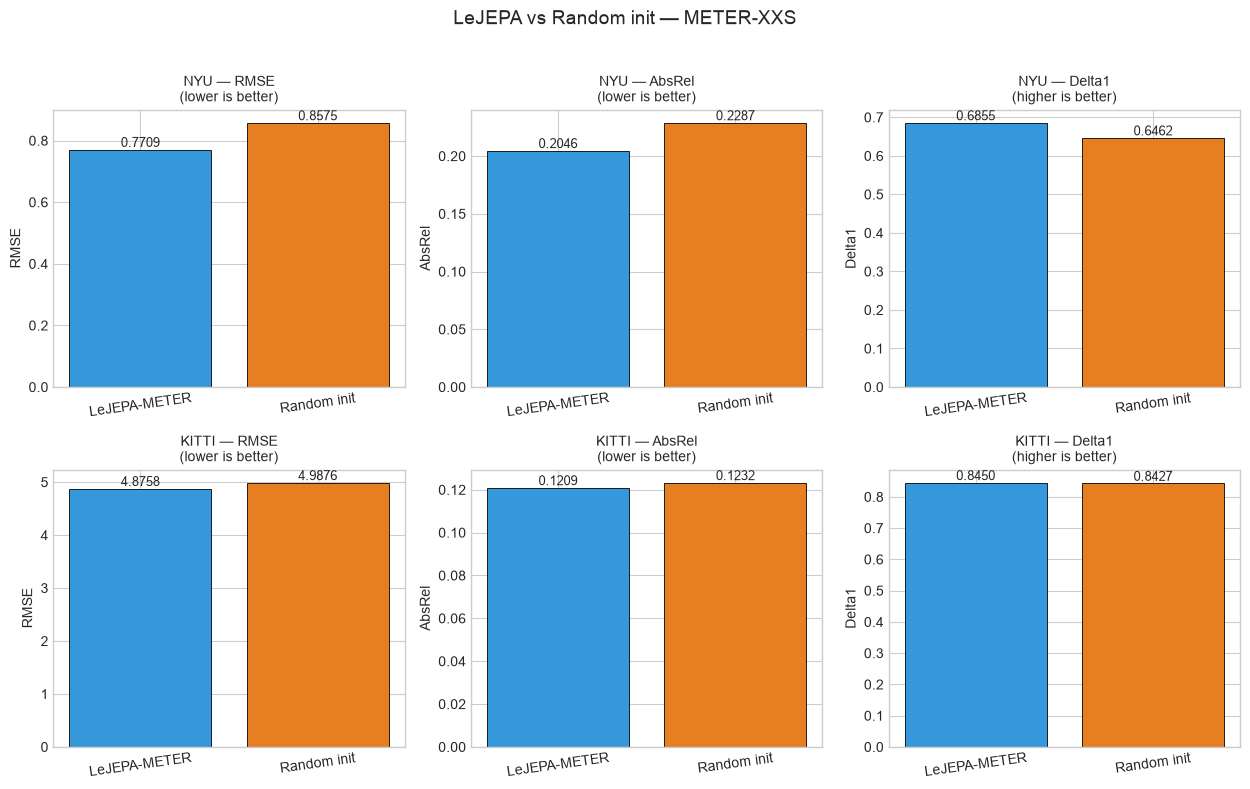


[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/compare_metrics_grid_xxs.pdf


In [11]:
print("=== COMPARATIVE BAR CHART ===")
if not results:
    print("[SKIP] no results to plot")
else:
    plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

    metric_specs = [
        ("RMSE",   "lower is better"),
        ("AbsRel", "lower is better"),
        ("Delta1", "higher is better"),
    ]

    datasets_present = [d for d in DATASETS if any((v, d) in results for v in VARIANTS)]
    n_rows = len(datasets_present)
    n_cols = len(metric_specs)
    if n_rows == 0:
        print("[SKIP] no dataset has any results")
    else:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4.0 * n_rows))
        if n_rows == 1:
            axes = np.expand_dims(axes, axis=0)

        for r, dataset in enumerate(datasets_present):
            variants_with_data = [v for v in VARIANTS if (v, dataset) in results]
            labels = [VARIANTS[v]["label"] for v in variants_with_data]
            colors = [VARIANTS[v]["color"] for v in variants_with_data]

            for c, (metric, direction) in enumerate(metric_specs):
                ax = axes[r, c]
                values = [results[(v, dataset)][metric] for v in variants_with_data]
                bars = ax.bar(labels, values, color=colors, edgecolor="black", linewidth=0.6)
                for bar, val in zip(bars, values):
                    h = bar.get_height()
                    ax.text(bar.get_x() + bar.get_width()/2, h, f"{val:.4f}",
                            ha="center", va="bottom", fontsize=9)
                ax.set_title(f"{dataset.upper()} — {metric}\n({direction})", fontsize=10)
                ax.set_ylabel(metric)
                ax.tick_params(axis="x", rotation=8)

        plt.suptitle(f"LeJEPA vs Random init — METER-{ARCH_NAME.upper()}", fontsize=14)
        plt.tight_layout(rect=[0, 0, 1, 0.96])

        bar_path = Path(IMAGES_DIR) / f"compare_metrics_grid_{ARCH_NAME}.pdf"
        plt.savefig(bar_path, dpi=140, bbox_inches="tight")
        plt.show()
        print(f"\n[OK] Saved → {bar_path}")


### 8 — Side-by-side depth predictions

One figure per dataset. Rows are samples, columns are: RGB | GT | predictions for each loaded variant.


=== DEPTH PREDICTIONS — NYU ===


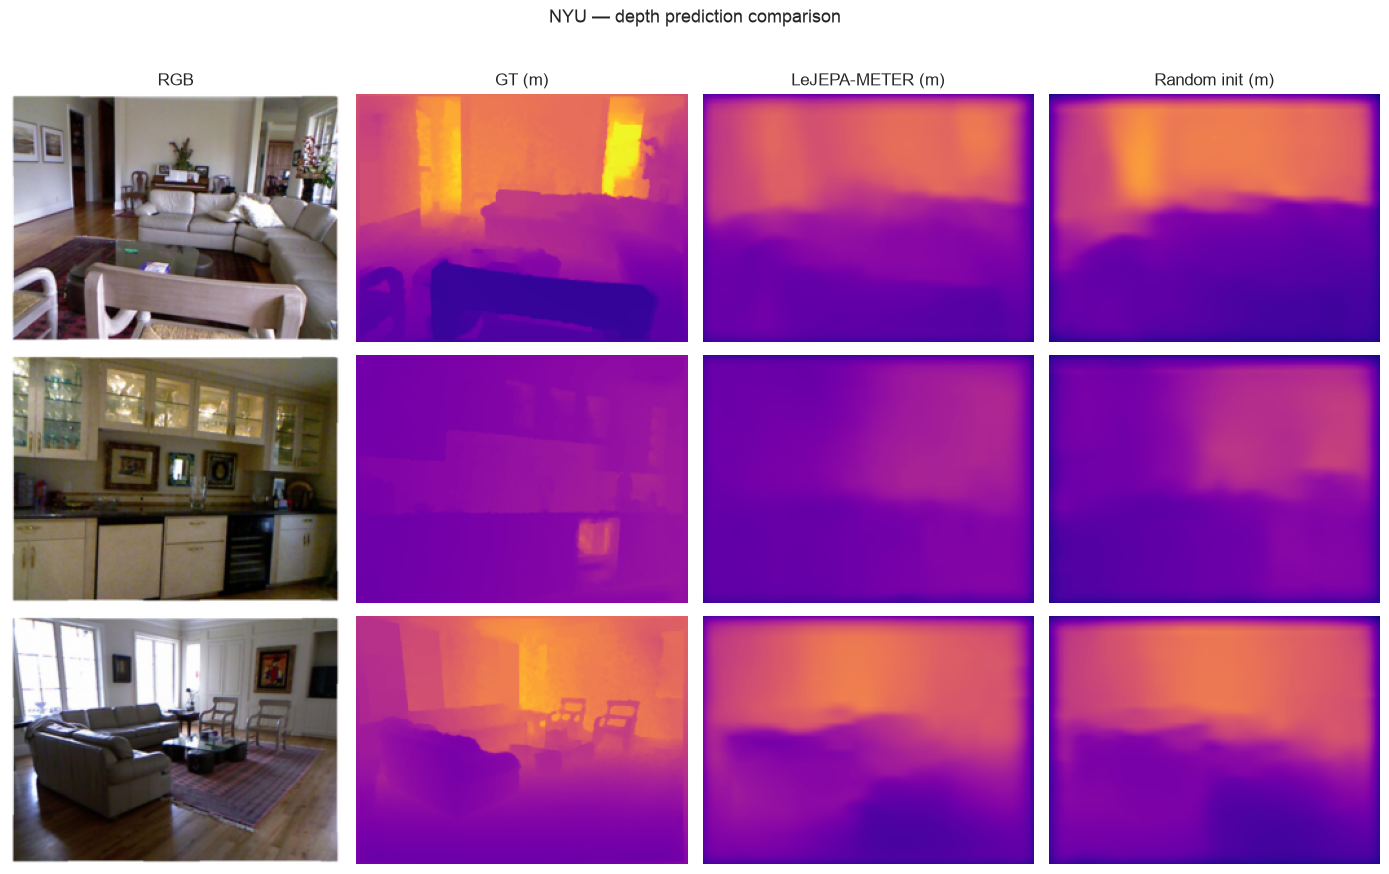

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/compare_predictions_nyu_xxs.pdf

=== DEPTH PREDICTIONS — KITTI ===


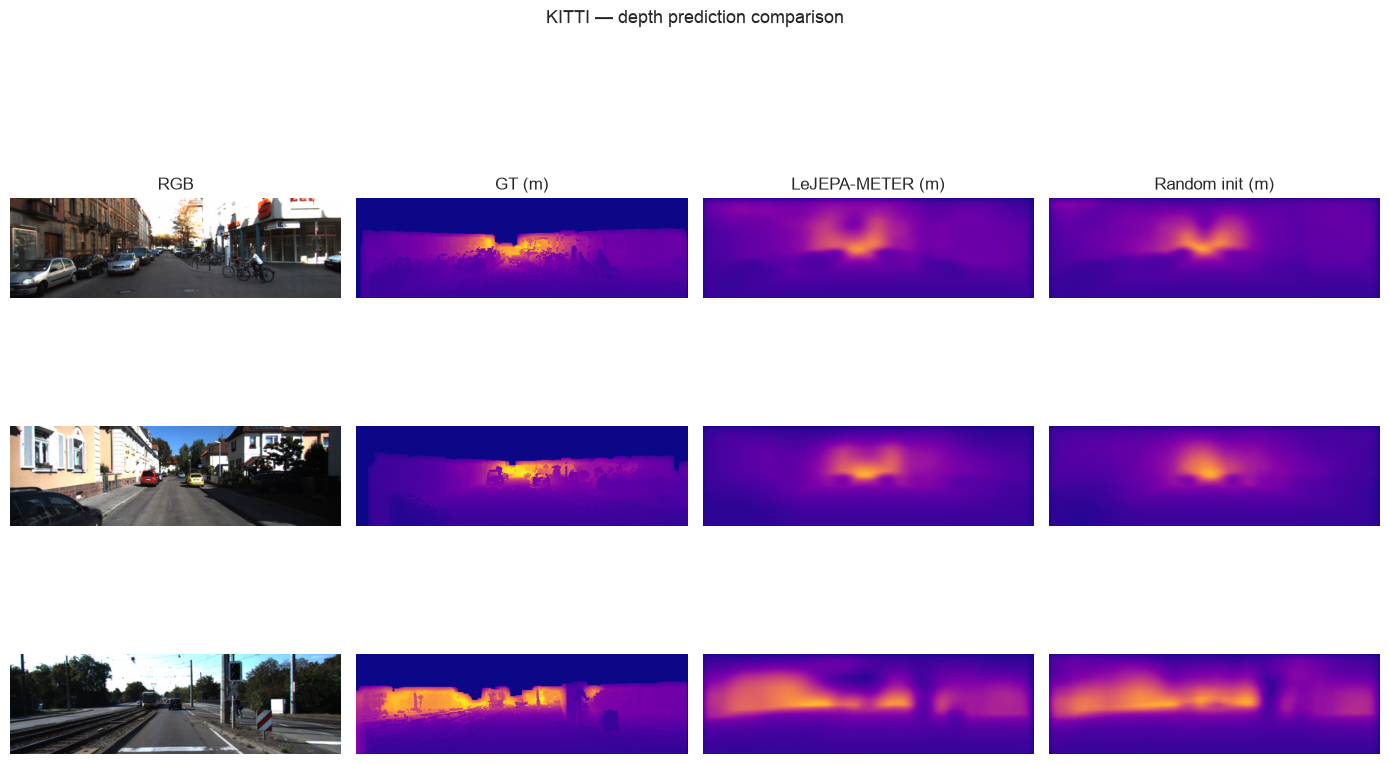

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/compare_predictions_kitti_xxs.pdf


In [12]:
for dataset in DATASETS:
    if dataset not in vis_loaders:
        print(f"\n[SKIP {dataset}] no vis loader")
        continue
    variants_with_data = [v for v in VARIANTS if (v, dataset) in models]
    if not variants_with_data:
        print(f"\n[SKIP {dataset}] no models loaded")
        continue

    print(f"\n=== DEPTH PREDICTIONS — {dataset.upper()} ===")

    batch = next(iter(vis_loaders[dataset]))
    rgb, depth_gt = batch
    rgb_show = denorm_rgb(rgb)

    # Unit conversion (NYU GT in cm → m)
    if dataset == "nyu":
        scale, unit, vmax = 1.0, "m", 10.0
    else:
        scale, unit, vmax = 1.0, "m", 80.0

    gt_m = depth_gt.cpu() * scale

    preds = {}
    for v in variants_with_data:
        pred = predict_depth(models[(v, dataset)], rgb, DEVICE) * scale
        preds[v] = pred

    n_samples = rgb.shape[0]
    n_cols = 2 + len(variants_with_data)   # RGB | GT | variant1 | variant2 ...
    fig, axes = plt.subplots(n_samples, n_cols, figsize=(3.5 * n_cols, 3.0 * n_samples))
    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n_samples):
        axes[i, 0].imshow(rgb_show[i].permute(1, 2, 0).numpy())
        axes[i, 0].set_title("RGB" if i == 0 else ""); axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_m[i, 0].numpy(), cmap="plasma", vmin=0, vmax=vmax)
        axes[i, 1].set_title(f"GT ({unit})" if i == 0 else ""); axes[i, 1].axis("off")

        for k, v in enumerate(variants_with_data):
            axes[i, 2 + k].imshow(preds[v][i, 0].numpy(), cmap="plasma", vmin=0, vmax=vmax)
            axes[i, 2 + k].set_title(f"{VARIANTS[v]['label']} ({unit})" if i == 0 else "")
            axes[i, 2 + k].axis("off")

    plt.suptitle(f"{dataset.upper()} — depth prediction comparison", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out = Path(IMAGES_DIR) / f"compare_predictions_{dataset}_{ARCH_NAME}.pdf"
    plt.savefig(out, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"[OK] Saved → {out}")


### 9 — Difference maps (paper Fig. 4/5 style)

Shows the per-pixel error magnitude |pred − GT| alongside the predictions.
The colormap is shared between the two variants for a fair comparison:
darker regions = lower error.



=== DIFFERENCE MAPS — NYU ===


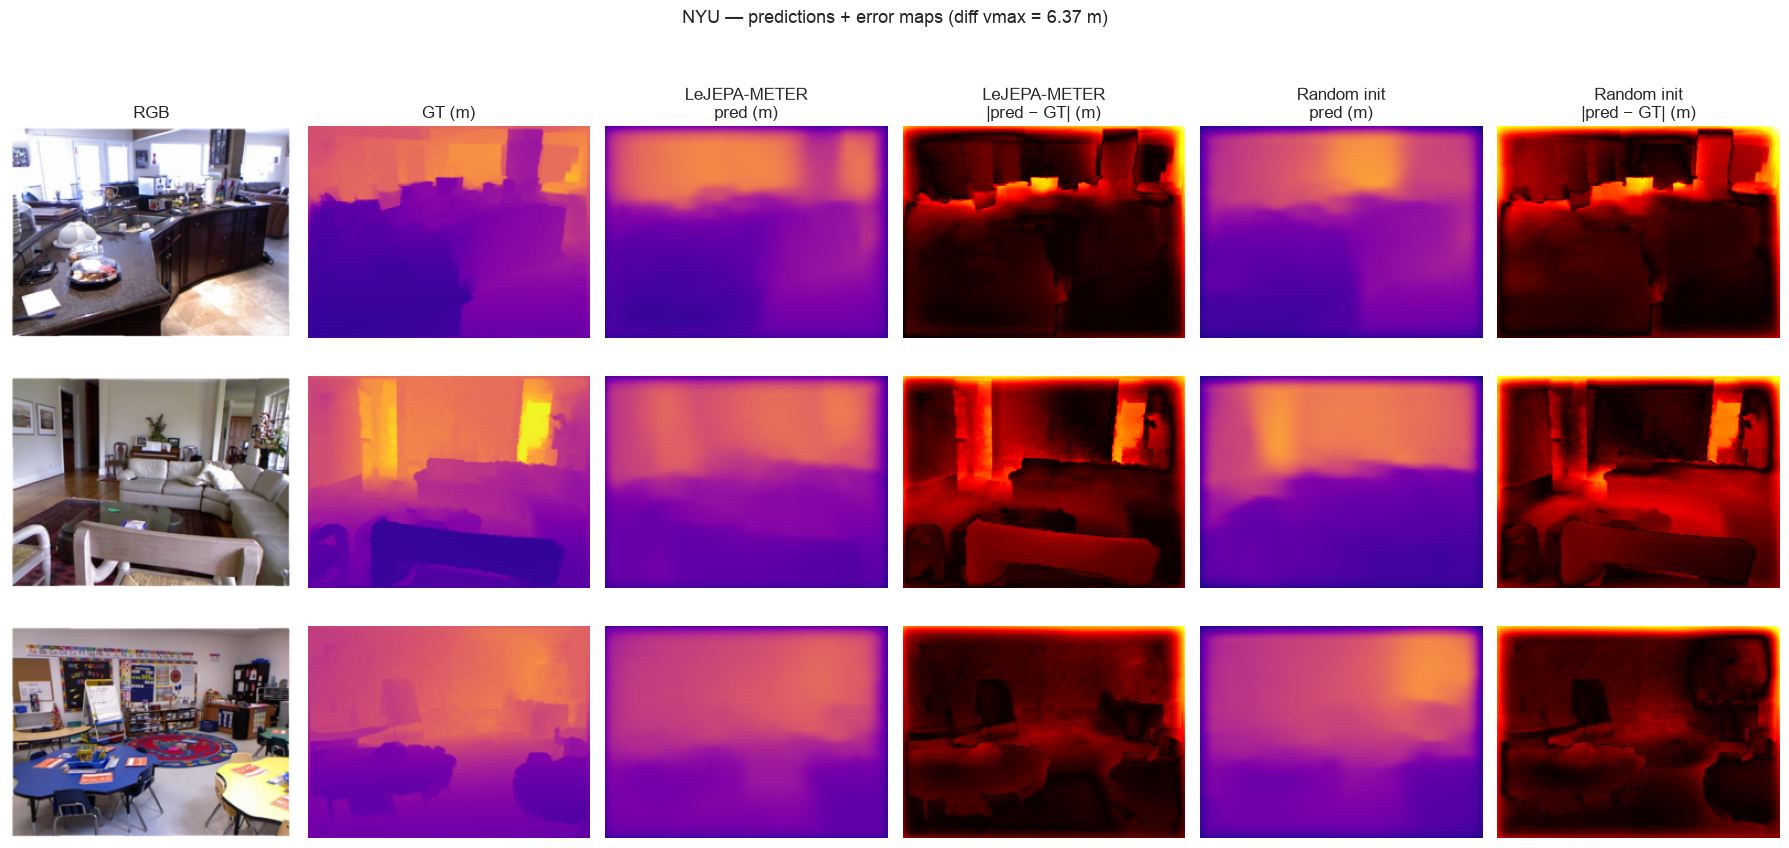

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/diff_maps_nyu_xxs.pdf

=== DIFFERENCE MAPS — KITTI ===


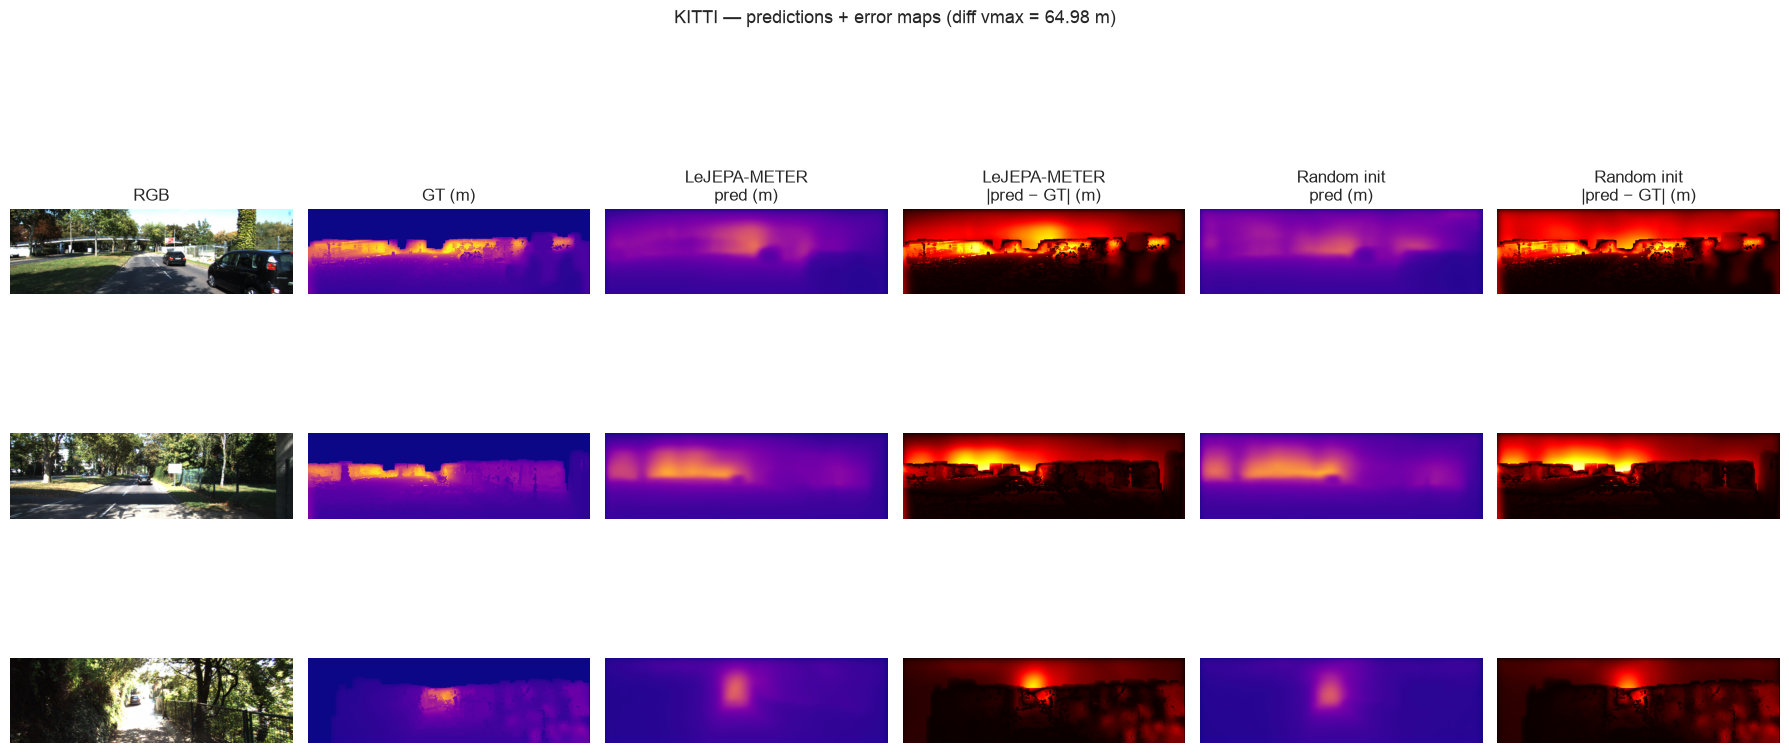

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/diff_maps_kitti_xxs.pdf


In [13]:
for dataset in DATASETS:
    if dataset not in vis_loaders:
        continue
    variants_with_data = [v for v in VARIANTS if (v, dataset) in models]
    if len(variants_with_data) < 1:
        continue

    print(f"\n=== DIFFERENCE MAPS — {dataset.upper()} ===")

    batch = next(iter(vis_loaders[dataset]))
    rgb, depth_gt = batch
    rgb_show = denorm_rgb(rgb)

    if dataset == "nyu":
        scale, unit, vmax = 1.0, "m", 10.0
    else:
        scale, unit, vmax = 1.0, "m", 80.0

    gt_m = depth_gt.cpu() * scale

    preds, diffs = {}, {}
    for v in variants_with_data:
        pred = predict_depth(models[(v, dataset)], rgb, DEVICE) * scale
        # Clamp consistently with the paper evaluation protocol
        pred = pred.clamp(min=1e-3, max=vmax)
        gt_clamped = gt_m.clamp(min=1e-3, max=vmax)
        preds[v] = pred
        diffs[v] = (pred - gt_clamped).abs()

    # Shared vmax across the two difference maps for fair comparison
    diff_vmax = max(d.max().item() for d in diffs.values())
    diff_vmax = max(diff_vmax, 0.5)   # Minimum floor

    n_samples = rgb.shape[0]
    n_cols = 2 + 2 * len(variants_with_data)   # RGB | GT | (pred + diff) per variant
    fig, axes = plt.subplots(n_samples, n_cols, figsize=(3.0 * n_cols, 3.0 * n_samples))
    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n_samples):
        axes[i, 0].imshow(rgb_show[i].permute(1, 2, 0).numpy())
        axes[i, 0].set_title("RGB" if i == 0 else ""); axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_m[i, 0].numpy(), cmap="plasma", vmin=0, vmax=vmax)
        axes[i, 1].set_title(f"GT ({unit})" if i == 0 else ""); axes[i, 1].axis("off")

        for k, v in enumerate(variants_with_data):
            col_p = 2 + 2 * k
            col_d = 3 + 2 * k
            axes[i, col_p].imshow(preds[v][i, 0].numpy(), cmap="plasma", vmin=0, vmax=vmax)
            axes[i, col_p].set_title(f"{VARIANTS[v]['label']}\npred ({unit})" if i == 0 else "")
            axes[i, col_p].axis("off")

            axes[i, col_d].imshow(diffs[v][i, 0].numpy(), cmap="hot", vmin=0, vmax=diff_vmax)
            axes[i, col_d].set_title(f"{VARIANTS[v]['label']}\n|pred − GT| ({unit})"
                                      if i == 0 else "")
            axes[i, col_d].axis("off")

    plt.suptitle(f"{dataset.upper()} — predictions + error maps "
                 f"(diff vmax = {diff_vmax:.2f} {unit})", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out = Path(IMAGES_DIR) / f"diff_maps_{dataset}_{ARCH_NAME}.pdf"
    plt.savefig(out, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"[OK] Saved → {out}")

### 10 — PCA probing — encoder features per (variant, dataset)

Side-by-side PCA visualization of the encoder features for each loaded variant. This shows whether LeJEPA pre-training produces a qualitatively different latent structure compared to random initialization, after fine-tuning.


=== PCA — NYU ===


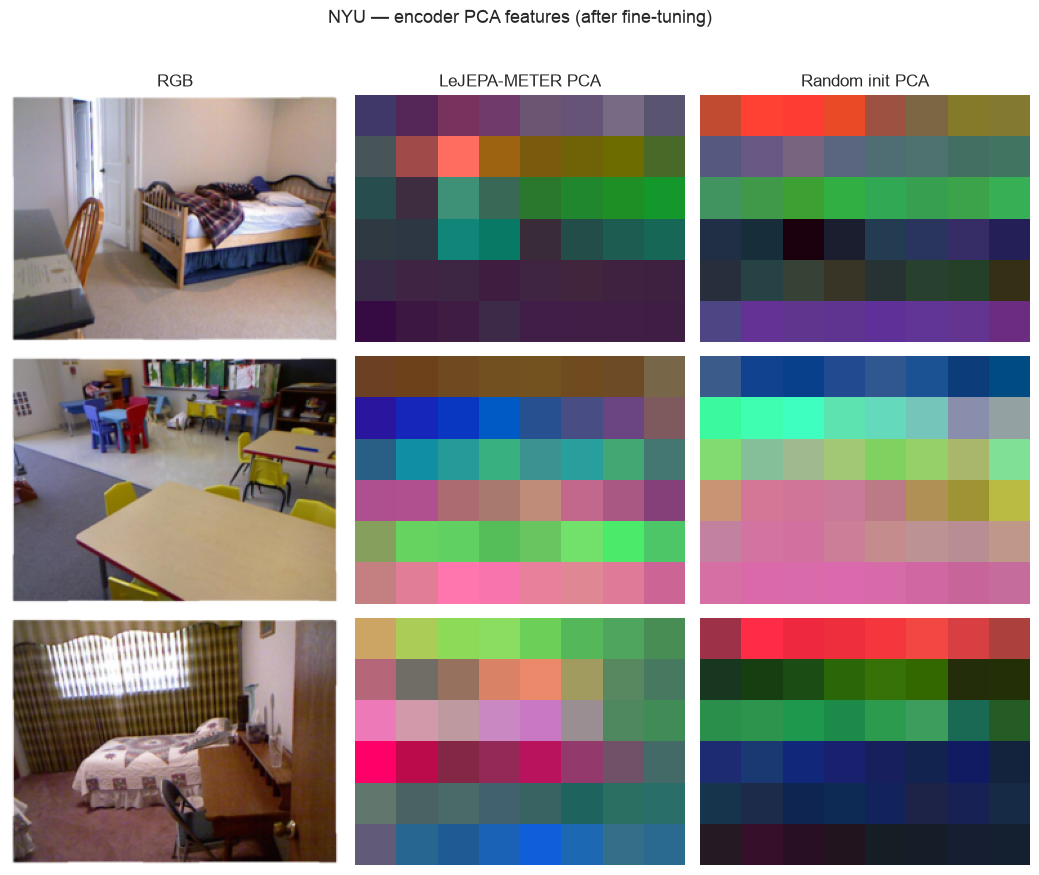

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.009926461..1.0000002].


[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/compare_pca_nyu_xxs.pdf

=== PCA — KITTI ===


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.005739658..1.0000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.018911175..1.0000002].


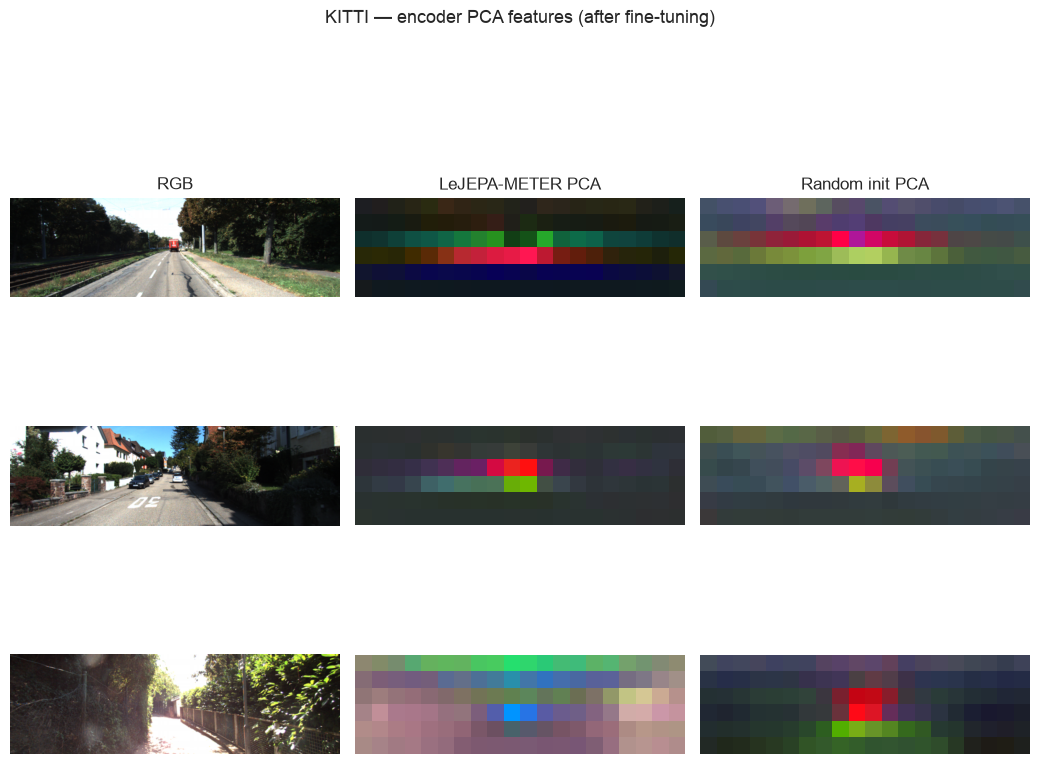

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/compare_pca_kitti_xxs.pdf


In [14]:
for dataset in DATASETS:
    if dataset not in vis_loaders:
        continue
    variants_with_data = [v for v in VARIANTS if (v, dataset) in models]
    if not variants_with_data:
        continue

    print(f"\n=== PCA — {dataset.upper()} ===")

    batch = next(iter(vis_loaders[dataset]))
    rgb = batch[0] if isinstance(batch, (list, tuple)) else batch
    rgb = rgb.to(DEVICE)
    rgb_show = rgb.cpu()

    n_samples = rgb.shape[0]
    n_cols = 1 + len(variants_with_data)
    fig, axes = plt.subplots(n_samples, n_cols, figsize=(3.5 * n_cols, 3.0 * n_samples))
    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n_samples):
        axes[i, 0].imshow(rgb_show[i].permute(1, 2, 0).numpy())
        axes[i, 0].set_title("RGB" if i == 0 else ""); axes[i, 0].axis("off")

        for k, v in enumerate(variants_with_data):
            feat = extract_features(models[(v, dataset)], rgb[i:i+1], DEVICE)
            pca_img = features_to_pca(feat)
            axes[i, 1 + k].imshow(pca_img)
            axes[i, 1 + k].set_title(f"{VARIANTS[v]['label']} PCA" if i == 0 else "")
            axes[i, 1 + k].axis("off")

    plt.suptitle(f"{dataset.upper()} — encoder PCA features (after fine-tuning)", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out = Path(IMAGES_DIR) / f"compare_pca_{dataset}_{ARCH_NAME}.pdf"
    plt.savefig(out, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"[OK] Saved → {out}")


### 11 — Latent space PCA scatter (global structure)

While the PCA in Section 8 shows per-pixel spatial features,
this projects ALL images from the test set into a 2D scatter plot
colored by average depth. If LeJEPA groups scenes by geometry,
you should observe colored clusters (close = similar depth).



=== PCA SCATTER — LeJEPA-METER | NYU ===

[INFO] Extracting embeddings for PCA scatter...
[INFO] Embeddings shape: (320, 160)
[INFO] Saved: /Volumes/Lexar/CV-project-25-26/output/images/pca_scatter_lejepa_nyu_xxs.pdf


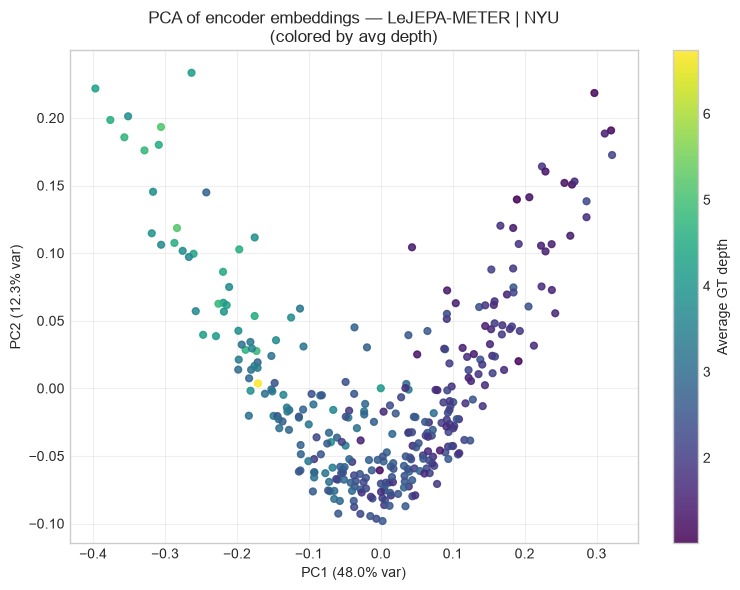


=== PCA SCATTER — Random init | NYU ===

[INFO] Extracting embeddings for PCA scatter...
[INFO] Embeddings shape: (320, 160)
[INFO] Saved: /Volumes/Lexar/CV-project-25-26/output/images/pca_scatter_from_scratch_nyu_xxs.pdf


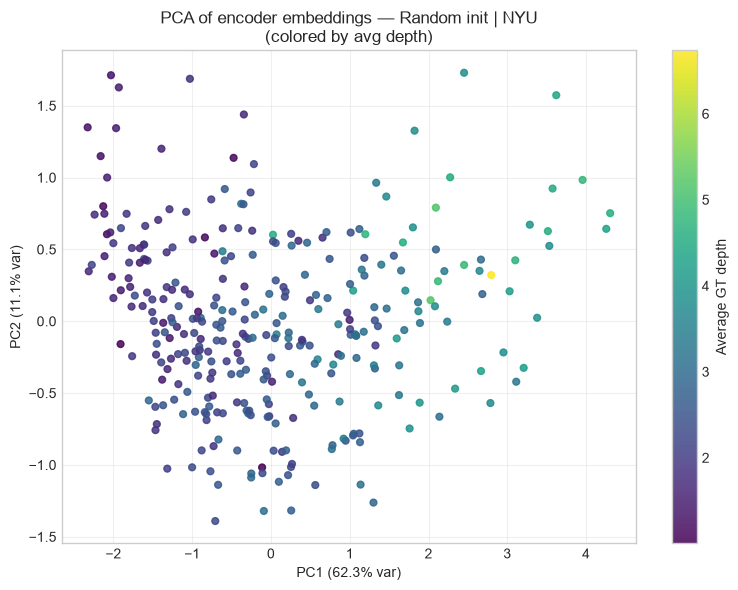


=== PCA SCATTER — LeJEPA-METER | KITTI ===

[INFO] Extracting embeddings for PCA scatter...
[INFO] Embeddings shape: (320, 160)
[INFO] Saved: /Volumes/Lexar/CV-project-25-26/output/images/pca_scatter_lejepa_kitti_xxs.pdf


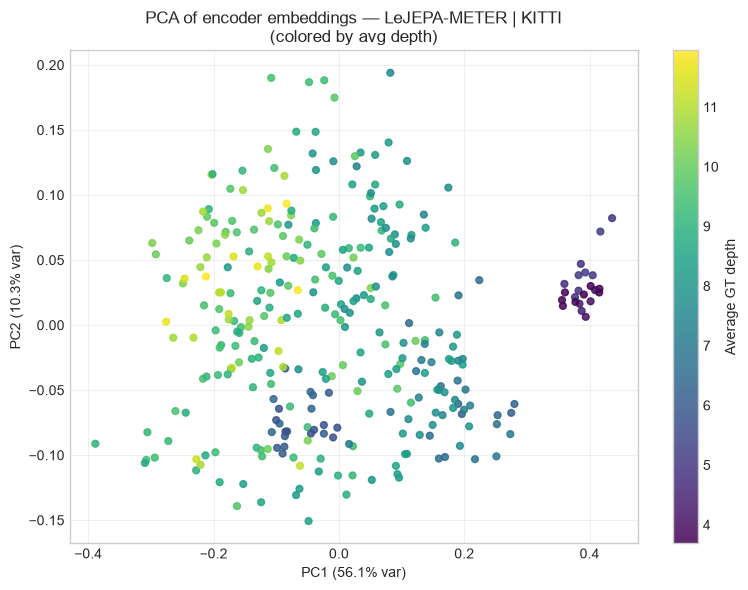


=== PCA SCATTER — Random init | KITTI ===

[INFO] Extracting embeddings for PCA scatter...
[INFO] Embeddings shape: (320, 160)
[INFO] Saved: /Volumes/Lexar/CV-project-25-26/output/images/pca_scatter_from_scratch_kitti_xxs.pdf


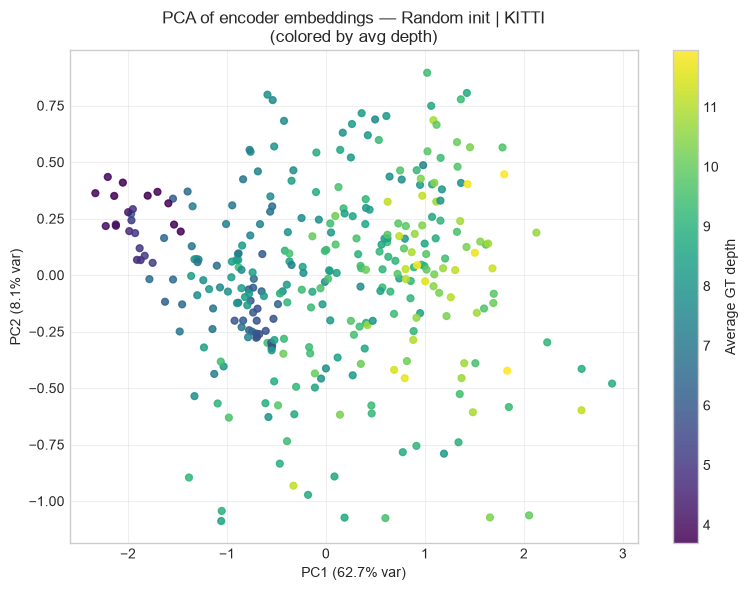

In [15]:
for dataset in DATASETS:
    if dataset not in test_loaders:
        continue
    for variant_key in VARIANTS:
        if (variant_key, dataset) not in models:
            continue
        label = VARIANTS[variant_key]["label"]
        print(f"\n=== PCA SCATTER — {label} | {dataset.upper()} ===")
        plot_pca_embeddings(
            model         = models[(variant_key, dataset)],
            dataloader    = test_loaders[dataset],
            device        = DEVICE,
            save_path     = Path(IMAGES_DIR) / f"pca_scatter_{variant_key}_{dataset}_{ARCH_NAME}.pdf",
            max_batches   = 20,
            dataset_name  = dataset,      
            variant_label = label,        
        )

### 12 — Efficiency benchmark (params + latency)

Run once — the architecture is identical across all variants, so latency and param count don't depend on the pre-training scheme.

In [16]:
print("=== EFFICIENCY BENCHMARK ===")
img_size_nyu   = (3, NYU_SIZE[0], NYU_SIZE[1])
img_size_kitti = (3, KITTI_SIZE[0], KITTI_SIZE[1])

# Use any loaded model — they share the architecture
sample_model = next(iter(models.values())) if models else METERFinetune(arch_type=ARCH_NAME)

eff_nyu   = benchmark_model(sample_model, img_size_nyu, device=DEVICE)   if "nyu"   in DATASETS else None
eff_kitti = benchmark_model(sample_model, img_size_kitti, device=DEVICE) if "kitti" in DATASETS else None

if eff_nyu:
    print(f"\n[NYU   {img_size_nyu}]   "
          f"params={eff_nyu['params_m']:.3f}M  "
          f"latency={eff_nyu['latency_ms']:.2f} ms  "
          f"fps={eff_nyu['fps']:.1f}")
if eff_kitti:
    print(f"[KITTI {img_size_kitti}] "
          f"params={eff_kitti['params_m']:.3f}M  "
          f"latency={eff_kitti['latency_ms']:.2f} ms  "
          f"fps={eff_kitti['fps']:.1f}")

efficiency = {"nyu": eff_nyu, "kitti": eff_kitti}


=== EFFICIENCY BENCHMARK ===
[INFO] Benchmark: 0.713M params | 13.00 ms/img | 77.0 FPS
[INFO] Benchmark: 0.713M params | 15.24 ms/img | 65.6 FPS

[NYU   (3, 192, 256)]   params=0.713M  latency=13.00 ms  fps=77.0
[KITTI (3, 192, 636)] params=0.713M  latency=15.24 ms  fps=65.6


### 13 — Convergence curves overlay

Reads the Lightning CSV logger output from each variant's log directory and overlays the `val/rmse` curves on the same plot, one subplot per dataset. Clearest visualization of *whether SSL pre-training converges faster*.

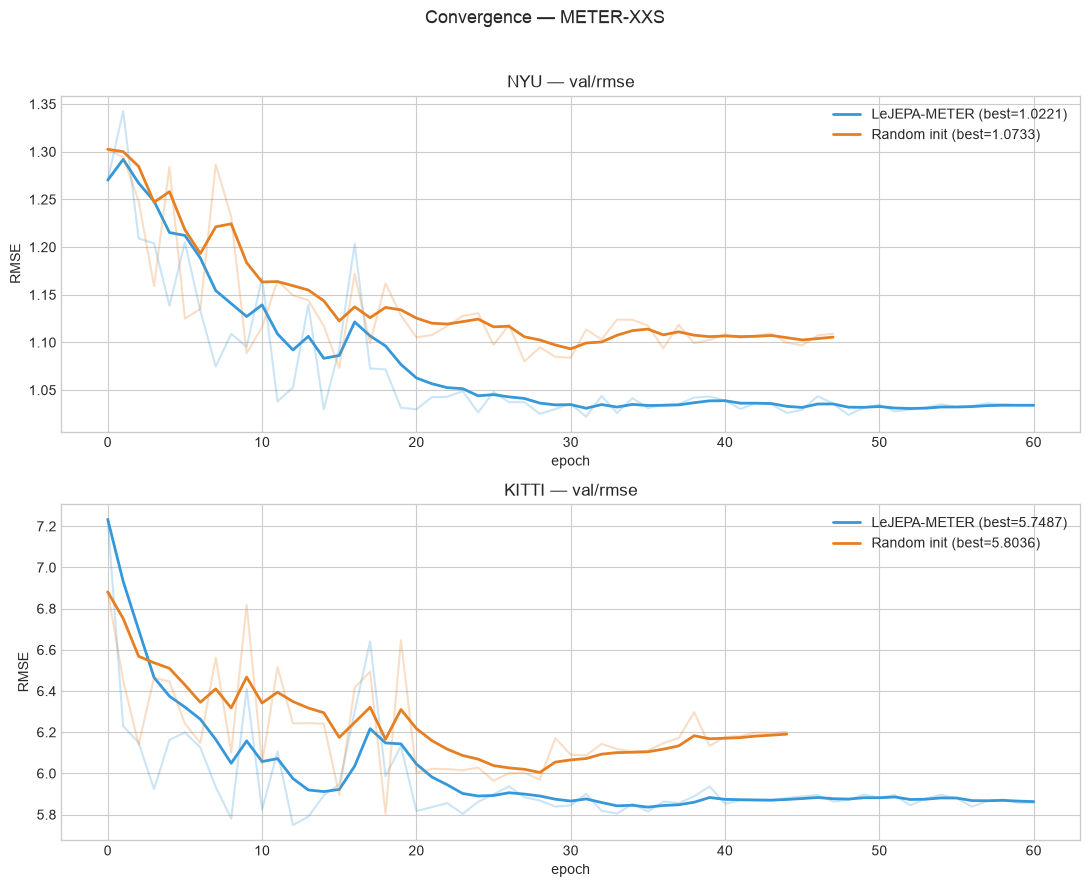


[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/convergence_overlay_xxs.pdf


In [17]:
datasets_with_data = [d for d in DATASETS if any((v, d) in results for v in VARIANTS)]
if not datasets_with_data:
    print("[SKIP] no datasets have results")
else:
    fig, axes = plt.subplots(len(datasets_with_data), 1,
                              figsize=(11, 4.5 * len(datasets_with_data)),
                              squeeze=False)
    axes = axes.flatten()

    for r, dataset in enumerate(datasets_with_data):
        ax = axes[r]
        plotted = 0
        for variant_key, vinfo in VARIANTS.items():
            log_name = vinfo["log_name"].format(dataset=dataset, ARCH_NAME=ARCH_NAME)
            csv_paths = find_logger_csvs(log_name)
            if not csv_paths:
                print(f"  [MISS] {vinfo['label']} | {dataset} — no CSV under {log_name}")
                continue
            try:
                dfs = [pd.read_csv(p) for p in csv_paths]
                df = pd.concat(dfs, ignore_index=True)
            except Exception as e:
                print(f"  [FAIL] {log_name}: {e}")
                continue

            ep, v = per_epoch(df, "val/rmse")
            if ep is None or len(ep) == 0:
                continue
            v_smooth = smooth(v, 0.7)
            ax.plot(ep, v,        color=vinfo["color"], alpha=0.25)
            ax.plot(ep, v_smooth, color=vinfo["color"], linewidth=2.0,
                    label=f"{vinfo['label']} (best={min(v):.4f})")
            plotted += 1

        ax.set_title(f"{dataset.upper()} — val/rmse")
        ax.set_xlabel("epoch"); ax.set_ylabel("RMSE")
        if plotted:
            ax.legend(loc="best")
        else:
            ax.text(0.5, 0.5, "no CSV logs found", ha="center", va="center", transform=ax.transAxes)

    plt.suptitle(f"Convergence — METER-{ARCH_NAME.upper()}", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    conv_path = Path(IMAGES_DIR) / f"convergence_overlay_{ARCH_NAME}.pdf"
    plt.savefig(conv_path, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"\n[OK] Saved → {conv_path}")


### 14 — Convergence speed quantification

Quantifies numerically how “SSL pre-training speeds up convergence” (Task Objective 3):

* best val/rmse and at which epoch
* val/rmse at fixed epochs (5, 10, 20, 30) to measure the initial convergence speed
* number of epochs required to reach 105% of the best score (proxy for “near-convergence”)


In [18]:
print("=== CONVERGENCE SPEED QUANTIFICATION ===\n")
conv_rows = []

for dataset in DATASETS:
    for variant_key, vinfo in VARIANTS.items():
        log_name = vinfo["log_name"].format(dataset=dataset, ARCH_NAME=ARCH_NAME)
        csv_paths = find_logger_csvs(log_name)
        if not csv_paths:
            continue
        try:
            dfs = [pd.read_csv(p) for p in csv_paths]
            df = pd.concat(dfs, ignore_index=True)
        except Exception:
            continue

        ep, v = per_epoch(df, "val/rmse")
        if ep is None or len(ep) == 0:
            continue

        best_idx   = int(np.argmin(v))
        best_rmse  = float(v[best_idx])
        best_epoch = int(ep[best_idx])

        # val/rmse at fixed epochs (NaN if the run is shorter)
        def at_epoch(target):
            mask = (ep == target)
            return float(v[mask][0]) if mask.any() else float("nan")

        # Epochs needed to get within 5% above the best value
        ep_to_near = first_epoch_reaching(ep, v, best_rmse * 1.05)

        conv_rows.append({
            "Dataset"          : dataset.upper(),
            "Variant"          : vinfo["label"],
            "Best RMSE"        : f"{best_rmse:.4f}",
            "Best epoch"       : best_epoch,
            "RMSE @ ep 5"      : f"{at_epoch(5):.4f}",
            "RMSE @ ep 10"     : f"{at_epoch(10):.4f}",
            "RMSE @ ep 20"     : f"{at_epoch(20):.4f}",
            "RMSE @ ep 30"     : f"{at_epoch(30):.4f}",
            "Epoch to 1.05×best": ep_to_near if ep_to_near is not None else "—",
        })

if conv_rows:
    conv_df = pd.DataFrame(conv_rows)
    print(conv_df.to_string(index=False))
    out_csv = Path(OUTPUT_DIR) / "csv" / f"convergence_speed_{ARCH_NAME}.csv"
    conv_df.to_csv(out_csv, index=False)
    print(f"\n[OK] Saved → {out_csv}")

    # Headline: does SSL really speed things up?
    print("\n=== CONVERGENCE HEADLINE ===")
    for dataset in DATASETS:
        rows = [r for r in conv_rows if r["Dataset"] == dataset.upper()]
        if len(rows) < 2:
            continue
        lej = next((r for r in rows if "LeJEPA" in r["Variant"]), None)
        rnd = next((r for r in rows if "Random" in r["Variant"]), None)
        if lej and rnd:
            try:
                lej_e10 = float(lej["RMSE @ ep 10"])
                rnd_e10 = float(rnd["RMSE @ ep 10"])
                gain_e10 = (rnd_e10 - lej_e10) / rnd_e10 * 100
                verdict = "✅ faster" if gain_e10 > 1 else ("⚠️ slower" if gain_e10 < -1 else "≈ same")
                print(f"  {dataset.upper():6s}  RMSE @ ep10: LeJEPA={lej_e10:.3f} vs "
                      f"Random={rnd_e10:.3f}  → {verdict} ({gain_e10:+.1f}%)")
            except Exception:
                pass
else:
    print("[SKIP] No convergence CSVs found")

=== CONVERGENCE SPEED QUANTIFICATION ===

Dataset      Variant Best RMSE  Best epoch RMSE @ ep 5 RMSE @ ep 10 RMSE @ ep 20 RMSE @ ep 30  Epoch to 1.05×best
    NYU LeJEPA-METER    1.0221          31      1.2050       1.1678       1.0298       1.0355                  11
    NYU  Random init    1.0733          15      1.1249       1.1162       1.1053       1.0839                   5
  KITTI LeJEPA-METER    5.7487          12      6.1989       5.8232       5.8174       5.8446                   3
  KITTI  Random init    5.8036          18      6.2423       6.0476       6.0025       6.0905                  10

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/csv/convergence_speed_xxs.csv

=== CONVERGENCE HEADLINE ===
  NYU     RMSE @ ep10: LeJEPA=1.168 vs Random=1.116  → ⚠️ slower (-4.6%)
  KITTI   RMSE @ ep10: LeJEPA=5.823 vs Random=6.048  → ✅ faster (+3.7%)


### 15 — Final unified comparison table

One row per `(dataset, variant)`. Adds a paper reference row per dataset for context. The `Δ RMSE` column shows the **absolute** RMSE difference between LeJEPA and random init (positive = LeJEPA worse, negative = LeJEPA better).

In [19]:
# Paper reference numbers (METER paper Table II — XXS row)
PAPER_REF = {
    "nyu"  : {"RMSE": 0.580, "AbsRel": 0.174, "Delta1": 0.744, "params_m": 0.71},
    "kitti": {"RMSE": 5.157, "AbsRel": 0.156, "Delta1": 0.782, "params_m": 0.71},
}

rows = []

# Paper reference rows (only if the arch is xxs — those are the published numbers)
if ARCH_NAME == "xxs":
    for dataset in DATASETS:
        ref = PAPER_REF[dataset]
        rows.append({
            "Dataset"        : dataset.upper(),
            "Variant"        : "Paper (Papa et al. 2024)",
            "RMSE"           : f"{ref['RMSE']:.4f}",
            "AbsRel"         : f"{ref['AbsRel']:.4f}",
            "Delta1"         : f"{ref['Delta1']:.4f}",
            "Params (M)"     : f"{ref['params_m']:.2f}",
            "Latency (ms)"   : "-",
            "Train time (s)" : "-",
        })

# Our runs
for dataset in DATASETS:
    eff = efficiency.get(dataset)
    lat = f"{eff['latency_ms']:.2f}" if eff else "-"
    for variant_key, vinfo in VARIANTS.items():
        key = (variant_key, dataset)
        if key not in results:
            continue
        r = results[key]
        rows.append({
            "Dataset"        : dataset.upper(),
            "Variant"        : vinfo["label"],
            "RMSE"           : f"{r['RMSE']:.4f}",
            "AbsRel"         : f"{r['AbsRel']:.4f}",
            "Delta1"         : f"{r['Delta1']:.4f}",
            "Params (M)"     : f"{eff['params_m']:.2f}" if eff else "-",
            "Latency (ms)"   : lat,
            "Train time (s)" : f"{r['train_time_sec']:.0f}" if r['train_time_sec'] else "-",
        })

# Compute Δ RMSE (LeJEPA - random init) per dataset
delta_rows = []
for dataset in DATASETS:
    if ("lejepa", dataset) in results and ("from_scratch", dataset) in results:
        d_rmse   = results[("lejepa", dataset)]["RMSE"]   - results[("from_scratch", dataset)]["RMSE"]
        d_absrel = results[("lejepa", dataset)]["AbsRel"] - results[("from_scratch", dataset)]["AbsRel"]
        d_delta1 = results[("lejepa", dataset)]["Delta1"] - results[("from_scratch", dataset)]["Delta1"]
        delta_rows.append({
            "Dataset"        : dataset.upper(),
            "Variant"        : "Δ (LeJEPA − Random init)",
            "RMSE"           : f"{d_rmse:+.4f}",
            "AbsRel"         : f"{d_absrel:+.4f}",
            "Delta1"         : f"{d_delta1:+.4f}",
            "Params (M)"     : "-",
            "Latency (ms)"   : "-",
            "Train time (s)" : "-",
        })

table = pd.DataFrame(rows + delta_rows)
print("=== FINAL COMPARISON TABLE ===\n")
print(table.to_string(index=False))

csv_path = Path(OUTPUT_DIR) / "csv" / f"compare_full_{ARCH_NAME}.csv"
table.to_csv(csv_path, index=False)
print(f"\n[OK] CSV saved → {csv_path}")

# Headline summary
print("\n=== HEADLINE ===")
for d_row in delta_rows:
    rmse_str = d_row["RMSE"]
    sign = float(rmse_str)
    verdict = "✅ LeJEPA helps" if sign < 0 else ("⚠️  LeJEPA hurts" if sign > 0 else "≈ Tied")
    print(f"  {d_row['Dataset']:7s}  ΔRMSE = {rmse_str}  →  {verdict}")


=== FINAL COMPARISON TABLE ===

Dataset                  Variant    RMSE  AbsRel  Delta1 Params (M) Latency (ms) Train time (s)
    NYU Paper (Papa et al. 2024)  0.5800  0.1740  0.7440       0.71            -              -
  KITTI Paper (Papa et al. 2024)  5.1570  0.1560  0.7820       0.71            -              -
    NYU             LeJEPA-METER  0.7709  0.2046  0.6855       0.71        13.00              -
    NYU              Random init  0.8575  0.2287  0.6462       0.71        13.00              -
  KITTI             LeJEPA-METER  4.8758  0.1209  0.8450       0.71        15.24              -
  KITTI              Random init  4.9876  0.1232  0.8427       0.71        15.24              -
    NYU Δ (LeJEPA − Random init) -0.0866 -0.0241 +0.0392          -            -              -
  KITTI Δ (LeJEPA − Random init) -0.1118 -0.0024 +0.0023          -            -              -

[OK] CSV saved → /Volumes/Lexar/CV-project-25-26/output/csv/compare_full_xxs.csv

=== HEADLINE ===
  NY

### 16 — Training cost vs accuracy (Task Objective 4)

Visualizes the **total training cost** (SSL pre-training + fine-tuning for LeJEPA,
fine-tuning only for random initialization) against the final RMSE. It answers the task question:
“Are the gains from LeJEPA worth the extra SSL pre-training cost?”


=== TRAINING COST vs ACCURACY (FLOPs) ===
  SSL NYU: 12500.68 TFLOPs
  SSL KITTI: 3948.45 TFLOPs



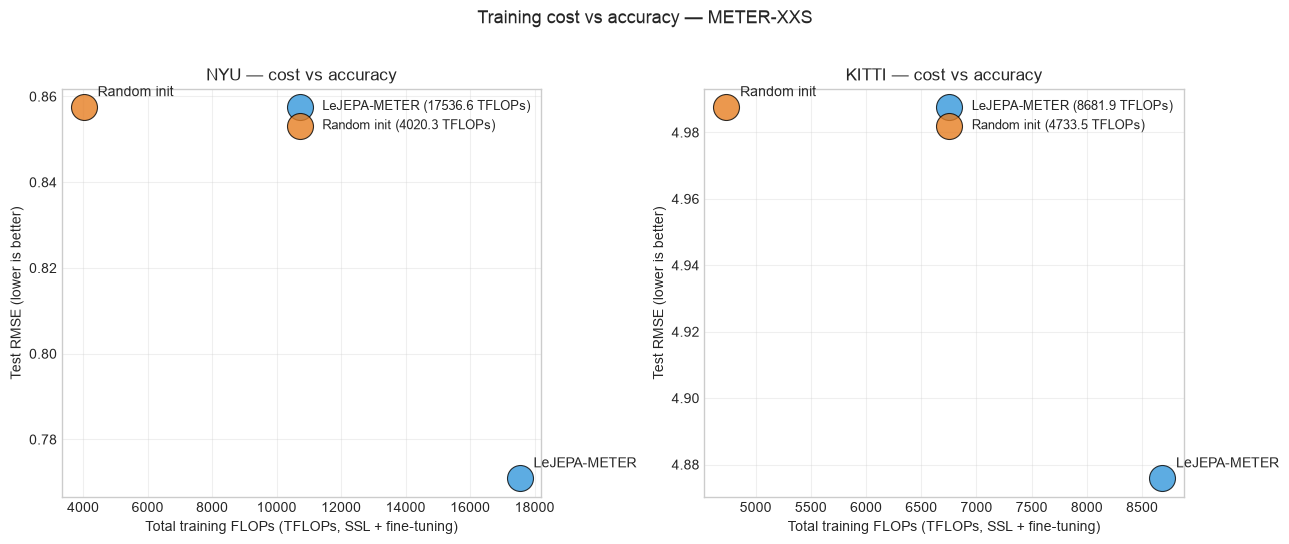

[OK] Saved → /Volumes/Lexar/CV-project-25-26/output/images/cost_vs_accuracy_xxs.pdf

=== COST-BENEFIT SUMMARY (FLOPs) ===
  NYU     Extra cost = +13516.3 TFLOPs  |  RMSE gain = +0.0866  (+10.1% relative)
  KITTI   Extra cost = +3948.5 TFLOPs  |  RMSE gain = +0.1118  (+2.2% relative)


In [20]:
print("=== TRAINING COST vs ACCURACY (FLOPs) ===")

# SSL pre-training FLOPs per dataset (from logger CSVs)
ssl_pretrain_flops = {}   # dataset -> flops

for dataset in DATASETS:
    ssl_log_name = f"lejepa_pretrain_{dataset}_{ARCH_NAME}"
    csv_paths = find_logger_csvs(ssl_log_name)
    if csv_paths:
        try:
            dfs = [pd.read_csv(p) for p in csv_paths]
            df = pd.concat(dfs, ignore_index=True)
            ssl_flops = extract_total_flops(
                df,
                ["ssl/cumulative_flops_epoch", "ssl/cumulative_flops_step"],
            )
            if ssl_flops is not None:
                ssl_pretrain_flops[dataset] = ssl_flops
                continue
        except Exception:
            pass

    ssl_pretrain_flops[dataset] = 0.0
    print(f"[WARN] No SSL pretrain FLOPs for {dataset} — using 0")

for dataset, f in ssl_pretrain_flops.items():
    print(f"  SSL {dataset.upper()}: {f/1e12:.2f} TFLOPs")
print()

# Build the scatter plot
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.5 * len(DATASETS), 5.5), squeeze=False)
axes = axes.flatten()

for ax_idx, dataset in enumerate(DATASETS):
    ax = axes[ax_idx]
    for variant_key, vinfo in VARIANTS.items():
        if (variant_key, dataset) not in results:
            continue

        log_name = vinfo["log_name"].format(dataset=dataset, ARCH_NAME=ARCH_NAME)
        csv_paths = find_logger_csvs(log_name)
        ft_flops = None
        if csv_paths:
            try:
                dfs = [pd.read_csv(p) for p in csv_paths]
                df = pd.concat(dfs, ignore_index=True)
                ft_flops = extract_total_flops(
                    df,
                    ["train/cumulative_flops_epoch", "train/cumulative_flops_step"],
                )
            except Exception:
                pass
        ft_flops = float(ft_flops or 0.0)

        # Total cost: SSL pre-training counts only for LeJEPA
        total_flops = ft_flops + (ssl_pretrain_flops.get(dataset, 0.0) if variant_key == "lejepa" else 0.0)
        total_tflops = total_flops / 1e12

        r = results[(variant_key, dataset)]
        ax.scatter(total_tflops, r["RMSE"],
                   s=350, alpha=0.8,
                   color=vinfo["color"], edgecolor="black", linewidth=0.8,
                   label=f"{vinfo['label']} ({total_tflops:.1f} TFLOPs)")
        ax.annotate(vinfo["label"], (total_tflops, r["RMSE"]),
                    textcoords="offset points", xytext=(10, 8), fontsize=10)

    ax.set_xlabel("Total training FLOPs (TFLOPs, SSL + fine-tuning)")
    ax.set_ylabel("Test RMSE (lower is better)")
    ax.set_title(f"{dataset.upper()} — cost vs accuracy")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=9)

plt.suptitle(f"Training cost vs accuracy — METER-{ARCH_NAME.upper()}", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])

out = Path(IMAGES_DIR) / f"cost_vs_accuracy_{ARCH_NAME}.pdf"
plt.savefig(out, dpi=140, bbox_inches="tight")
plt.show()
print(f"[OK] Saved → {out}")

# How much does SSL cost relative to the gain? Final number for the report
print("\n=== COST-BENEFIT SUMMARY (FLOPs) ===")
for dataset in DATASETS:
    if ("lejepa", dataset) in results and ("from_scratch", dataset) in results:
        lej = results[("lejepa", dataset)]
        rnd = results[("from_scratch", dataset)]

        log_lej = VARIANTS["lejepa"]["log_name"].format(dataset=dataset, ARCH_NAME=ARCH_NAME)
        log_rnd = VARIANTS["from_scratch"]["log_name"].format(dataset=dataset, ARCH_NAME=ARCH_NAME)
        csv_lej = find_logger_csvs(log_lej)
        csv_rnd = find_logger_csvs(log_rnd)

        def _ft_flops(paths):
            if not paths:
                return 0.0
            try:
                dfs = [pd.read_csv(p) for p in paths]
                df = pd.concat(dfs, ignore_index=True)
                return float(extract_total_flops(
                    df,
                    ["train/cumulative_flops_epoch", "train/cumulative_flops_step"],
                ) or 0.0)
            except Exception:
                return 0.0

        lej_ft = _ft_flops(csv_lej)
        rnd_ft = _ft_flops(csv_rnd)
        total_extra_flops = (ssl_pretrain_flops.get(dataset, 0.0) + lej_ft) - rnd_ft
        rmse_gain = rnd["RMSE"] - lej["RMSE"]
        print(f"  {dataset.upper():6s}  Extra cost = {total_extra_flops/1e12:+.1f} TFLOPs  "
              f"|  RMSE gain = {rmse_gain:+.4f}  "
              f"({rmse_gain/rnd['RMSE']*100:+.1f}% relative)")

### 17 — RELATIVE IMPROVEMENT 

  RELATIVE IMPROVEMENT — LeJEPA vs Random Init

━━━ NYU ━━━
  RMSE     Random=0.8575  LeJEPA=0.7709  Δabs=+0.0866m  Δrel=++10.10%  ✅ LeJEPA helps
  AbsRel   Random=0.2287  LeJEPA=0.2046  Δabs=+0.0241  Δrel=++10.53%  ✅ LeJEPA helps
  Delta1   Random=0.6462  LeJEPA=0.6855  Δabs=+0.0392  Δrel=++6.07%  ✅ LeJEPA helps

━━━ KITTI ━━━
  RMSE     Random=4.9876  LeJEPA=4.8758  Δabs=+0.1118m  Δrel=++2.24%  ✅ LeJEPA helps
  AbsRel   Random=0.1232  LeJEPA=0.1209  Δabs=+0.0024  Δrel=++1.92%  ✅ LeJEPA helps
  Delta1   Random=0.8427  LeJEPA=0.8450  Δabs=+0.0023  Δrel=++0.27%  ≈ tied

[OK] CSV saved → /Volumes/Lexar/CV-project-25-26/output/csv/improvement_summary_xxs.csv


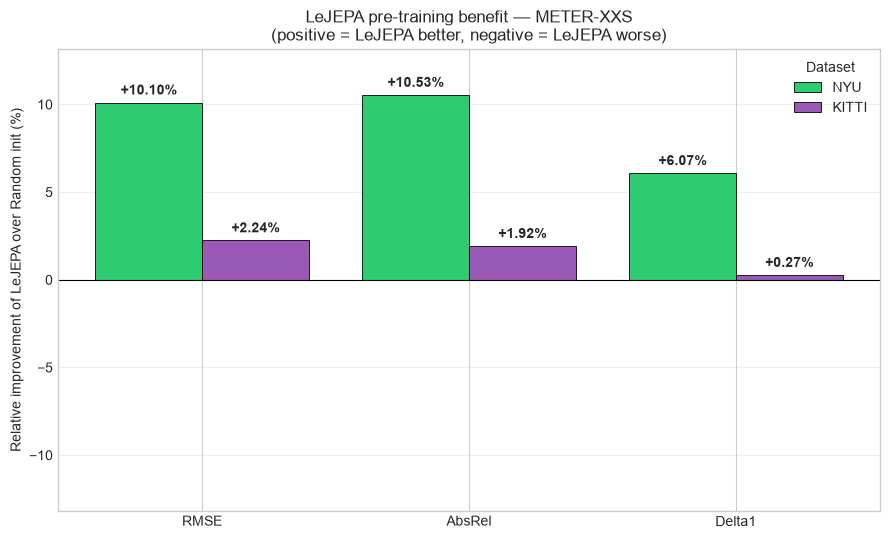

[OK] Chart saved → /Volumes/Lexar/CV-project-25-26/output/images/improvement_summary_xxs.pdf


In [21]:
print("=" * 70)
print("  RELATIVE IMPROVEMENT — LeJEPA vs Random Init")
print("=" * 70)
print()

# Direction-aware sign convention:
#  - RMSE, AbsRel: lower is better → improvement = (random - lejepa) / random * 100
#  - Delta1      : higher is better → improvement = (lejepa - random) / random * 100
METRICS = [
    ("RMSE",   "lower",  "m"),
    ("AbsRel", "lower",  ""),
    ("Delta1", "higher", ""),
]

improvement_rows = []
chart_data = {}   # {dataset: {metric: rel_delta_pct}}

for dataset in DATASETS:
    if (("lejepa", dataset) not in results or
        ("from_scratch", dataset) not in results):
        print(f"[SKIP {dataset.upper()}] — missing one of the two variants")
        continue

    lej = results[("lejepa",       dataset)]
    rnd = results[("from_scratch", dataset)]

    print(f"━━━ {dataset.upper()} ━━━")
    chart_data[dataset] = {}
    for metric_name, direction, unit in METRICS:
        v_lej = lej[metric_name]
        v_rnd = rnd[metric_name]
        if direction == "lower":
            abs_delta = v_rnd - v_lej
            rel_delta = abs_delta / v_rnd * 100
        else:
            abs_delta = v_lej - v_rnd
            rel_delta = abs_delta / v_rnd * 100

        sign_str = "+" if rel_delta >= 0 else ""
        verdict  = "✅ LeJEPA helps" if rel_delta > 0.5 else (
                   "⚠️  LeJEPA hurts" if rel_delta < -0.5 else
                   "≈ tied")

        print(f"  {metric_name:7s}  Random={v_rnd:.4f}  LeJEPA={v_lej:.4f}  "
              f"Δabs={abs_delta:+.4f}{unit}  Δrel={sign_str}{rel_delta:+.2f}%  {verdict}")

        improvement_rows.append({
            "Dataset"      : dataset.upper(),
            "Metric"       : metric_name,
            "Random init"  : f"{v_rnd:.4f}",
            "LeJEPA"       : f"{v_lej:.4f}",
            "Δ abs"        : f"{abs_delta:+.4f}",
            "Δ relative"   : f"{sign_str}{rel_delta:+.2f}%",
            "Verdict"      : verdict,
        })
        chart_data[dataset][metric_name] = rel_delta
    print()

# Save CSV for the report
if improvement_rows:
    imp_df = pd.DataFrame(improvement_rows)
    out_csv = Path(OUTPUT_DIR) / "csv" / f"improvement_summary_{ARCH_NAME}.csv"
    imp_df.to_csv(out_csv, index=False)
    print(f"[OK] CSV saved → {out_csv}")


# ============================================================
# Grouped bar chart: relative improvement (%) per metric × dataset
# ============================================================
if chart_data:
    metrics_to_plot = [m[0] for m in METRICS]
    datasets_to_plot = list(chart_data.keys())
    n_metrics  = len(metrics_to_plot)
    n_datasets = len(datasets_to_plot)

    x       = np.arange(n_metrics)
    width   = 0.8 / n_datasets
    palette = {"nyu": "#2ecc71", "kitti": "#9b59b6"}  

    fig, ax = plt.subplots(figsize=(9, 5.5))

    for i, dataset in enumerate(datasets_to_plot):
        vals = [chart_data[dataset].get(m, 0.0) for m in metrics_to_plot]
        offsets = x + (i - (n_datasets - 1) / 2) * width
        bars = ax.bar(offsets, vals, width,
                      color=palette.get(dataset, "#888888"),
                      edgecolor="black", linewidth=0.6,
                      label=dataset.upper())
        # Numeric labels on top/bottom of each bar
        for bar, v in zip(bars, vals):
            h = bar.get_height()
            va = "bottom" if h >= 0 else "top"
            offset = 0.3 if h >= 0 else -0.3
            ax.text(bar.get_x() + bar.get_width() / 2, h + offset,
                    f"{v:+.2f}%", ha="center", va=va, fontsize=10,
                    fontweight="bold")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_to_plot)
    ax.set_ylabel("Relative improvement of LeJEPA over Random init (%)")
    ax.set_title(f"LeJEPA pre-training benefit — METER-{ARCH_NAME.upper()}\n"
                 "(positive = LeJEPA better, negative = LeJEPA worse)",
                 fontsize=12)
    ax.legend(loc="best", title="Dataset")
    ax.grid(axis="y", alpha=0.3)

    # Symmetric y-limit for clean visualization
    all_vals = [v for d in chart_data.values() for v in d.values()]
    ymax = max(abs(min(all_vals)), abs(max(all_vals))) * 1.25
    ymax = max(ymax, 5.0)   # at least ±5%
    ax.set_ylim(-ymax, ymax)

    plt.tight_layout()
    out_pdf = Path(IMAGES_DIR) / f"improvement_summary_{ARCH_NAME}.pdf"
    plt.savefig(out_pdf, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[OK] Chart saved → {out_pdf}")

---
## Done

All comparative artifacts saved under:
- `output/json/results_<variant>_<dataset>_<arch>.json` — per-config metrics
- `output/images/compare_metrics_grid_<arch>.pdf` — bar chart 2×3
- `output/images/compare_predictions_<dataset>_<arch>.pdf` — depth predictions side-by-side
- `output/images/compare_pca_<dataset>_<arch>.pdf` — encoder PCA per variant
- `output/images/convergence_overlay_<arch>.pdf` — val/rmse overlay
- `output/csv/compare_full_<arch>.csv` — full table

The CSV is what you put in the report.